In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import(accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay)
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (Dense, Dropout, Input, Flatten, MaxPooling2D, Conv2D)
from tensorflow.keras.callbacks import EarlyStopping

In [4]:
train_df = pd.read_csv(r"C:\Users\DELL\OneDrive\Documents\Deep Learning\CNN MNIST\train.csv")


In [5]:
print("Train data shape:", train_df.shape)


Train data shape: (42000, 785)


In [7]:
print(train_df.head(5))

   label  pixel0  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  \
0      1       0       0       0       0       0       0       0       0   
1      0       0       0       0       0       0       0       0       0   
2      1       0       0       0       0       0       0       0       0   
3      4       0       0       0       0       0       0       0       0   
4      0       0       0       0       0       0       0       0       0   

   pixel8  ...  pixel774  pixel775  pixel776  pixel777  pixel778  pixel779  \
0       0  ...         0         0         0         0         0         0   
1       0  ...         0         0         0         0         0         0   
2       0  ...         0         0         0         0         0         0   
3       0  ...         0         0         0         0         0         0   
4       0  ...         0         0         0         0         0         0   

   pixel780  pixel781  pixel782  pixel783  
0         0         0         

In [8]:
train_df["label"].value_counts().sort_index()

label
0    4132
1    4684
2    4177
3    4351
4    4072
5    3795
6    4137
7    4401
8    4063
9    4188
Name: count, dtype: int64

In [9]:
X = train_df.drop("label", axis=1).values
y = train_df["label"].values
plt.figure(figsize=(10, 4))

<Figure size 1000x400 with 0 Axes>

<Figure size 1000x400 with 0 Axes>

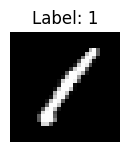

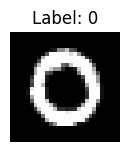

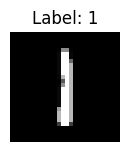

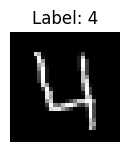

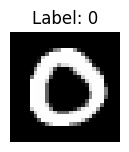

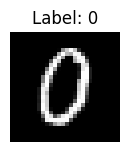

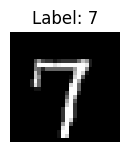

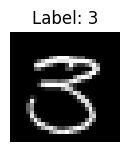

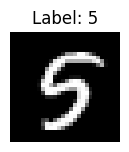

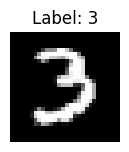

In [11]:
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(X[i].reshape(28, 28), cmap="gray")
    plt.title(f"Label: {y[i]}")
    plt.axis("off")
    plt.tight_layout()
    plt.show()

In [12]:
X = X.astype("float32") / 255.0
X = X.reshape(-1, 28, 28, 1)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [13]:
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("y_train:", y_train.shape)
print("y_val:", y_val.shape)

X_train: (33600, 28, 28, 1)
X_val: (8400, 28, 28, 1)
y_train: (33600,)
y_val: (8400,)


In [14]:
model = Sequential([Input(shape=(28, 28, 1)),  
                    Conv2D(32, (3, 3), activation='relu', padding='same'),
                    MaxPooling2D((2, 2)),
                    Conv2D(64, (3, 3), activation='relu', padding='same'),
                    MaxPooling2D((2, 2)),
                    Flatten(),
                    Dense(128, activation='relu'),
                    Dropout(0.3),
                    Dense(10, activation="softmax")
                    ])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 421,642 (1.61 MB)

 Trainable params: 421,642 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

In [15]:
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [16]:
early_stop = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)

In [17]:
history = model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=15, batch_size=64, callbacks=[early_stop], verbose=1)

Epoch 1/15
525/525 ━━━━━━━━━━━━━━━━━━━━ 25s 15ms/step - accuracy: 0.9196 - loss: 0.2610 - val_accuracy: 0.9721 - val_loss: 0.0856
Epoch 2/15
525/525 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.9749 - loss: 0.0817 - val_accuracy: 0.9811 - val_loss: 0.0605
Epoch 3/15
525/525 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.9817 - loss: 0.0590 - val_accuracy: 0.9840 - val_loss: 0.0489
Epoch 4/15
525/525 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - accuracy: 0.9860 - loss: 0.0459 - val_accuracy: 0.9838 - val_loss: 0.0544
Epoch 5/15
525/525 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.9879 - loss: 0.0372 - val_accuracy: 0.9875 - val_loss: 0.0421
Epoch 6/15
525/525 ━━━━━━━━━━━━━━━━━━━━ 8s 15ms/step - accuracy: 0.9904 - loss: 0.0302 - val_accuracy: 0.9882 - val_loss: 0.0402
Epoch 7/15
525/525 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.9914 - loss: 0.0274 - val_accuracy: 0.9882 - val_loss: 0.0415
Epoch 8/15
525/525 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.9935 - loss: 0.0206 - val_acc

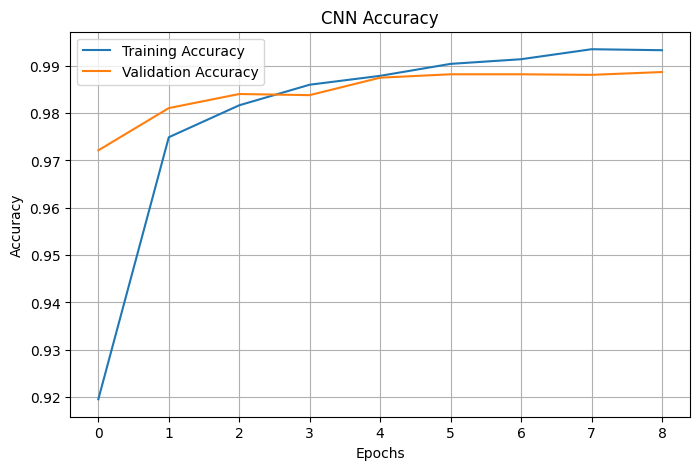

In [18]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("CNN Accuracy")
plt.legend()
plt.grid(True)
plt.show()

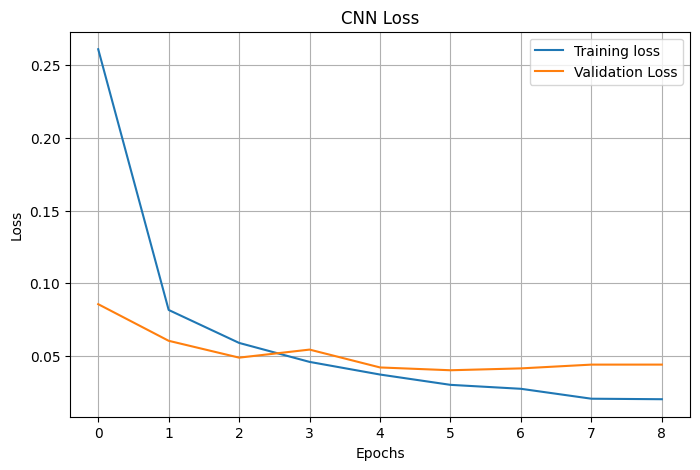

In [19]:
plt.figure(figsize=(8, 5))
plt.plot(history.history['loss'], label="Training loss")
plt.plot(history.history['val_loss'], label="Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("CNN Loss")
plt.legend()
plt.grid(True)
plt.show()

              precision    recall  f1-score   support

           0     0.9963    0.9891    0.9927       827
           1     0.9852    0.9979    0.9915       937
           2     0.9881    0.9904    0.9892       835
           3     0.9908    0.9851    0.9879       870
           4     0.9877    0.9889    0.9883       814
           5     0.9907    0.9776    0.9841       759
           6     0.9833    0.9964    0.9898       827
           7     0.9943    0.9864    0.9903       880
           8     0.9889    0.9828    0.9858       813
           9     0.9775    0.9857    0.9816       838

    accuracy                         0.9882      8400
   macro avg     0.9883    0.9880    0.9881      8400
weighted avg     0.9882    0.9882    0.9882      8400



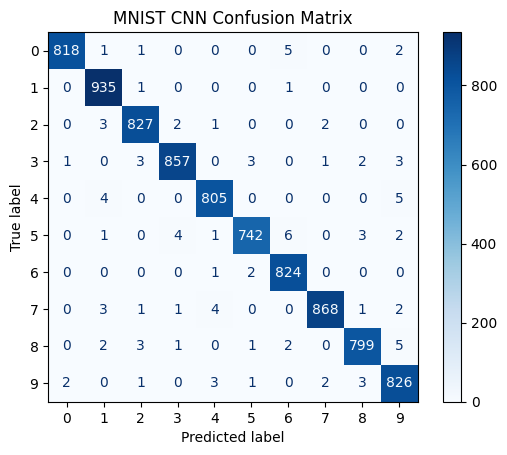

In [20]:
y_prob = model.predict(X_val, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
print(classification_report(y_val, y_pred, digits=4))
cm = confusion_matrix(y_val, y_pred)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=np.arange(10))
display.plot(cmap="Blues", values_format='d')
plt.title("MNIST CNN Confusion Matrix")
plt.show()

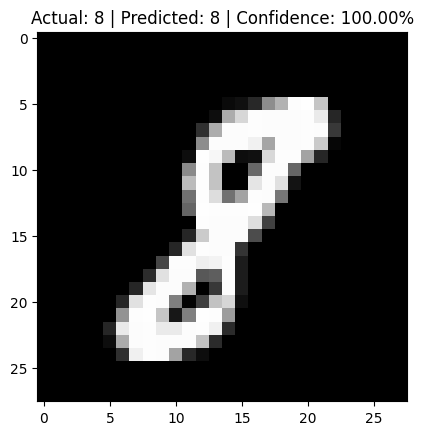

Predicted Digit: 8
Model confidence: 100.00%


In [21]:
index  = 10
image = X_val[index]
true_digit = y_val[index]
probabilities = model.predict(image[np.newaxis, ...], verbose=0)[0]
predicted_digit = np.argmax(probabilities)
confidence = np.max(probabilities)*100
plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Actual: {true_digit} | Predicted: {predicted_digit} | Confidence: {confidence:.2f}%")
plt.show()
print(f"Predicted Digit: {predicted_digit}")
print(f"Model confidence: {confidence:.2f}%")

In [22]:
test_df = pd.read_csv(r"C:\Users\DELL\OneDrive\Documents\Deep Learning\CNN MNIST\test.csv")

In [23]:
X_kaggle_test = test_df.values.astype("float32") / 255.0
X_kaggle_test = X_kaggle_test.reshape(-1, 28, 28, 1)
test_probabilities = model.predict(X_kaggle_test, batch_size=64, verbose=1)
test_predictions = np.argmax(test_probabilities, axis=1)
submission = pd.DataFrame({"ImageId": np.arange(1, len(test_predictions)+1), 
                           "Label": test_predictions
                           })

438/438 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [24]:
submission.to_csv("submission.csv", index=False)
print(submission.head())
print("Submission file created successfully!")

   ImageId  Label
0        1      2
1        2      0
2        3      9
3        4      9
4        5      3
Submission file created successfully!
